# 02 · What the brain sees: answer sequences
**Kuizi brain walkthrough, notebook 2 of 10**

The brain never sees a student's face or name. It sees a **sequence of interactions**: which item,
which concept, right or wrong, how long the answer took, how long since the previous answer,
how many hints. In production these come from the telemetry pipeline as events.

We use two sources, both safe on a PC:
1. **ASSISTments 2009**: real (anonymous) answers from 4,217 middle-school students on maths
   skills. Public research data (Feng, Heffernan & Koedinger, 2009). The first run downloads it
   once (64 MB) into `ml/data/`.
2. **The Kuizi simulator**: simulated Bac Physics students on the concept graph from notebook 1.
   We know each simulated student's *true* mastery, so later notebooks can check whether a
   model finds it.

| In this notebook | Production ticket |
| --- | --- |
| Event taxonomy and schemas | T023 |
| Telemetry SDK (elapsed time, hesitation) | T024 |
| Synthetic learner data generator | T219 |
| Online sequence builder | T048 |

<div dir="rtl" lang="ar">

## ٠٢ · ماذا يرى الدماغ: متتاليات الإجابات

الدماغ لا يرى وجه التلميذ ولا اسمه. يرى <b>متتالية من التفاعلات</b>: أي تمرين، أي مفهوم، صحيح أم خاطئ،
كم استغرقت الإجابة، كم مرّ من الوقت منذ الإجابة السابقة، وكم تلميحًا طلب.

نستعمل مصدرين آمنين على الحاسوب:
١. <b>ASSISTments 2009</b>: إجابات حقيقية ومجهولة الهوية لـ4,217 تلميذًا في الرياضيات، بيانات بحثية عامة.
٢. <b>محاكي كويزي</b>: تلاميذ باكالوريا فيزياء افتراضيون على خريطة المفاهيم. نعرف التمكّن <b>الحقيقي</b> لكل تلميذ،
فنستطيع لاحقًا أن نتحقّق هل وجده النموذج أم لا.

</div>

In [1]:
# Concept: loading real answer sequences · Production: T023, T040
from kuizi_brain import data as D
df = D.load_assist2009()
print(f"{len(df):,} answers, {df.student.nunique():,} students, {df.item.nunique():,} items, {df.kc.nunique()} concepts")
df.head(8)

258,153 answers, 3,628 students, 15,901 items, 145 concepts


,student,item,kc,kc_name,correct,elapsed_s,hints
0,0,11749,57,Circle Graph,0,26.271,2
1,0,11773,57,Circle Graph,1,29.123,0
2,0,11766,57,Circle Graph,0,13.779,2
3,0,11785,57,Circle Graph,0,16.901,2
4,0,11786,57,Circle Graph,0,11.079,2
5,0,11781,57,Circle Graph,0,8.244,2
6,0,11789,56,Circle Graph,0,21.884,3
7,0,2678,58,Circle Graph,0,59.891,0


In [2]:
# Concept: one student's history, in order · Production: T048
one = df[df.student == df.student.iloc[0]]
one[["item", "kc_name", "correct", "elapsed_s", "hints"]].head(15)

,item,kc_name,correct,elapsed_s,hints
0,11749,Circle Graph,0,26.271,2
1,11773,Circle Graph,1,29.123,0
2,11766,Circle Graph,0,13.779,2
3,11785,Circle Graph,0,16.901,2
4,11786,Circle Graph,0,11.079,2
5,11781,Circle Graph,0,8.244,2
6,11789,Circle Graph,0,21.884,3
7,2678,Circle Graph,0,59.891,0
8,2867,Circle Graph,1,64.234,0
9,2662,Circle Graph,0,82.572,0


## Students learn while they practise

Group answers by **opportunity**: the 1st, 2nd, 3rd… time a student meets the same concept. If
students learn, the share of right answers should rise. This *learning curve* is exactly what
knowledge tracing models.

<div dir="rtl" lang="ar">

## التلاميذ يتعلّمون أثناء التمرّن

نجمع الإجابات حسب <b>الفرصة</b>: المرّة الأولى والثانية والثالثة… التي يلتقي فيها التلميذ بنفس المفهوم.
إذا كان التلاميذ يتعلّمون، فيجب أن ترتفع نسبة الإجابات الصحيحة. هذا <b>منحنى التعلّم</b> هو بالضبط ما يتتبّعه الدماغ.

</div>

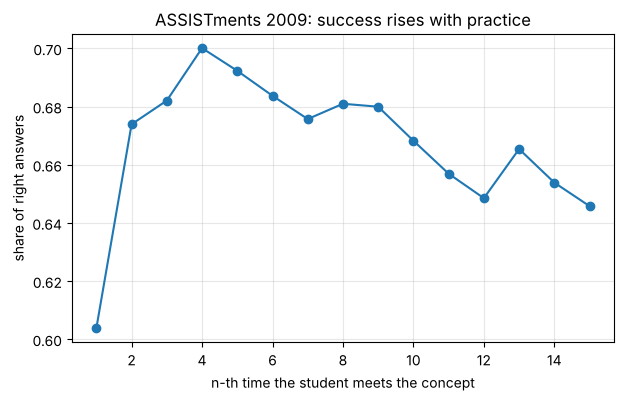

opportunity,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
mean,0.604,0.674,0.682,0.7,0.692,0.684,0.676,0.681,0.68,0.668,0.657,0.649,0.665,0.654,0.646
size,42016.000,31476.000,25165.000,21933.0,18231.000,14856.000,12396.000,10428.000,8986.00,7780.000,6395.000,5616.000,4982.000,4371.000,3845.000


In [3]:
# Concept: learning curve (success by practice opportunity) · Production: T040, T047
import matplotlib.pyplot as plt
df["opportunity"] = df.groupby(["student", "kc"]).cumcount() + 1
curve = df[df.opportunity <= 15].groupby("opportunity").correct.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve.index, curve["mean"], marker="o")
ax.set_xlabel("n-th time the student meets the concept")
ax.set_ylabel("share of right answers")
ax.set_title("ASSISTments 2009: success rises with practice")
ax.grid(alpha=.3)
plt.show()
curve.round(3).T

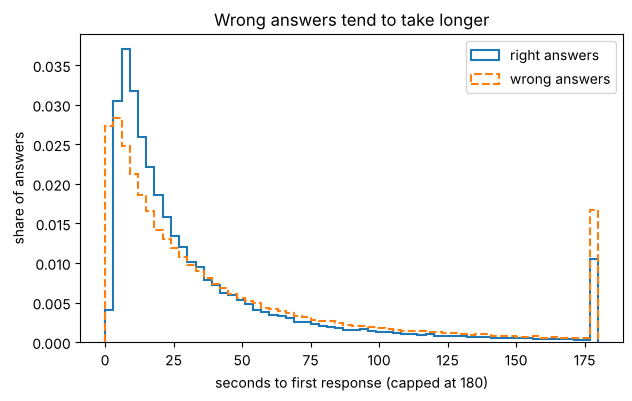

In [4]:
# Concept: elapsed time (how long an answer takes) · Production: T024
fig, ax = plt.subplots(figsize=(7, 4))
for c, label, style in [(1, "right answers", "-"), (0, "wrong answers", "--")]:
    ax.hist(df[df.correct == c].elapsed_s.clip(upper=180), bins=60, histtype="step", ls=style, lw=1.5, label=label, density=True)
ax.set_xlabel("seconds to first response (capped at 180)")
ax.set_ylabel("share of answers")
ax.legend()
ax.set_title("Wrong answers tend to take longer")
plt.show()

## The simulator: students whose real knowledge we know

ASSISTments has no timestamps (so no "time since last answer") and, like all real data, never
tells us what the student *really* knew. The simulator fills both gaps. It also includes students
with an official accommodation (extra time, sometimes a screen reader): they answer more slowly
but know just as much. Notebook 10 uses them to test fairness.

<div dir="rtl" lang="ar">

## المحاكي: تلاميذ نعرف معرفتهم الحقيقية

ASSISTments لا يحتوي على توقيت الإجابات (فلا يوجد "الوقت منذ آخر إجابة")، ومثل كل البيانات الحقيقية لا يخبرنا
بما كان التلميذ <b>يعرفه فعلًا</b>. المحاكي يسدّ الثغرتين. وفيه أيضًا تلاميذ لهم تيسيرات رسمية (وقت إضافي، وأحيانًا قارئ
شاشة): يجيبون أبطأ لكنهم يعرفون بنفس القدر. سنستعملهم في الدفتر ١٠ لاختبار الإنصاف.

</div>

In [5]:
# Concept: simulated Bac Physics students · Production: T219
sim = D.simulate_students(n_students=300, answers_per_student=120, seed=1)
print(f"{len(sim):,} simulated answers; {sim.correct.mean():.0%} right; "
      f"{(sim.time_multiplier > 1).groupby(sim.student).first().mean():.0%} of students have extra time")
sim[["student", "kc_name", "correct", "elapsed_s", "lag_s", "hints", "time_multiplier", "p_true"]].head(10).round(2)

36,000 simulated answers; 54% right; 15% of students have extra time


,student,kc_name,correct,elapsed_s,lag_s,hints,time_multiplier,p_true
0,0,Dérivées,0,48.67,6.75,2,1.0,0.28
1,0,Dérivées,1,89.61,34.41,1,1.0,0.31
2,0,Dérivées,0,84.58,5.95,1,1.0,0.38
3,0,Dérivées,0,65.73,94.75,0,1.0,0.28
4,0,Dérivées,0,79.23,44.25,1,1.0,0.26
5,0,Dérivées,0,86.03,29.64,0,1.0,0.35
6,0,Vecteurs et repères,0,66.06,19.00,2,1.0,0.23
7,0,Dérivées,0,72.69,47.53,0,1.0,0.27
8,0,Vecteurs et repères,1,51.90,48.97,0,1.0,0.38
9,0,Dérivées,0,86.81,136.38,1,1.0,0.33


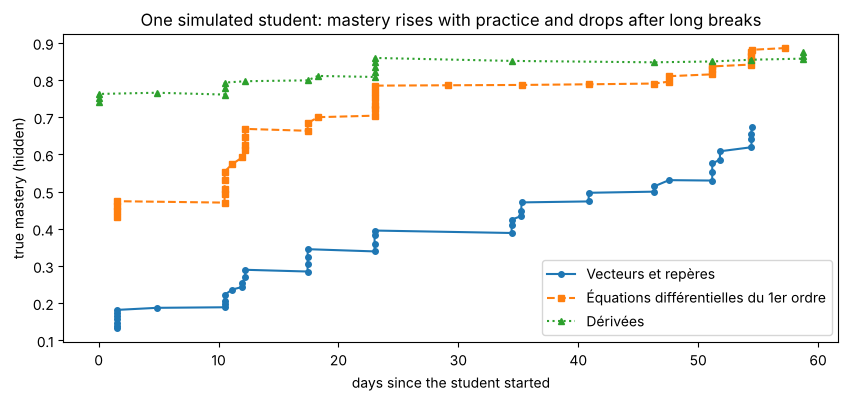

In [6]:
# Concept: hidden truth: learning and forgetting over time · Production: T219, T054
s0 = sim[sim.student == 3]
fig, ax = plt.subplots(figsize=(10, 4))
for kc, style in zip(s0.kc_id.value_counts().index[:3], ["-o", "--s", ":^"]):
    part = s0[s0.kc_id == kc]
    ax.plot(part.t / 86400, part.mastery_true, style, label=part.kc_name.iloc[0], ms=4)
ax.set_xlabel("days since the student started")
ax.set_ylabel("true mastery (hidden)")
ax.set_title("One simulated student: mastery rises with practice and drops after long breaks")
ax.legend()
plt.show()

## What the model actually receives

Models read fixed-length **windows** of 100 answers. Ids are shifted by one so that 0 means
"padding" (empty slot), and a **mask** marks the real answers. Times are put on a log scale so
that 10 s vs 20 s matters as much as 100 s vs 200 s.

<div dir="rtl" lang="ar">

## ماذا يستقبل النموذج فعلًا

تقرأ النماذج <b>نوافذ</b> بطول ثابت من 100 إجابة. نزيح الأرقام بواحد كي يعني 0 "خانة فارغة"، و<b>القناع</b>
يحدّد الإجابات الحقيقية. نضع الأوقات على سلّم لوغاريتمي كي يكون الفرق بين 10 و20 ثانية بأهمية الفرق بين 100 و200 ثانية.

</div>

In [7]:
# Concept: windows, padding and mask · Production: T048
from kuizi_brain import models as M
w = M.make_windows(sim)
print({k: tuple(v.shape) for k, v in w.items()})
print("first window, first 8 steps")
print("  concept:", w["kc"][0, :8].tolist())
print("  correct:", w["correct"][0, :8].tolist())
print("  elapsed:", [round(x, 2) for x in w["elapsed"][0, :8].tolist()])
print("  mask   :", w["mask"][0, :8].tolist())

{'item': (600, 100), 'kc': (600, 100), 'correct': (600, 100), 'elapsed': (600, 100), 'lag': (600, 100), 'mask': (600, 100), 'student': (600, 100)}
first window, first 8 steps
  concept: [1, 1, 1, 1, 1, 1, 2, 1]
  correct: [0, 1, 0, 0, 0, 0, 0, 0]
  elapsed: [0.78, 0.9, 0.89, 0.84, 0.88, 0.89, 0.84, 0.86]
  mask   : [True, True, True, True, True, True, True, True]


### Remember
- The brain's input is a sequence: item, concept, right/wrong, time taken, time since last answer, hints.
- Success rises with practice (the learning curve) and drops after long breaks (forgetting).
- Real data never reveals true knowledge; the simulator does, which lets us test models honestly.
- Only public or simulated data on a PC. Real Kuizi student data never goes here.

<div dir="rtl" lang="ar">

### تذكّر
- مدخل الدماغ متتالية: التمرين، المفهوم، صحيح/خاطئ، الوقت المستغرق، الوقت منذ آخر إجابة، التلميحات.
- النجاح يرتفع مع التمرّن (منحنى التعلّم) وينخفض بعد الانقطاع الطويل (النسيان).
- البيانات الحقيقية لا تكشف المعرفة الحقيقية؛ المحاكي يكشفها، فنختبر النماذج بنزاهة.
- على الحاسوب بيانات عامة أو محاكاة فقط، ولا توضع بيانات تلاميذ كويزي الحقيقيين هنا أبدًا.

</div>